In [34]:
# ===== Setup =====
import os, json, re, random, urllib.request
import numpy as np
import pandas as pd

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
print("OK, imports fine")

OK, imports fine


In [35]:
# ===== Load the data =====
train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")
print(train.shape, test.shape)
train.head()

(10003, 2) (3080, 2)


,text,category
0,I am still waiting on my card?,card_arrival
1,What can I do if my card still hasn't arrived ...,card_arrival
2,I have been waiting over a week. Is the card s...,card_arrival
3,Can I track my card while it is in the process...,card_arrival
4,"How do I know if I will get my card, or if it ...",card_arrival


In [36]:
# Some labels have capital letters or a "?" at the end, we clean them
train["intent"] = train["category"].str.lower().str.rstrip("?")
test["intent"] = test["category"].str.lower().str.rstrip("?")
print(train["intent"].nunique(), test["intent"].nunique())

77 77


In [37]:
SECURITE = [  # imposed by the subject
    "compromised_card", "lost_or_stolen_card", "lost_or_stolen_phone",
    "card_payment_not_recognised", "cash_withdrawal_not_recognised",
    "direct_debit_payment_not_recognised",
]

CARTES = [  # the card itself: get it, activate it, use it, PIN
    "activate_my_card", "apple_pay_or_google_pay", "atm_support", "card_about_to_expire",
    "card_acceptance", "card_arrival", "card_delivery_estimate", "card_linking",
    "card_not_working", "card_swallowed", "change_pin", "contactless_not_working",
    "disposable_card_limits", "get_disposable_virtual_card", "get_physical_card",
    "getting_spare_card", "getting_virtual_card", "order_physical_card", "pin_blocked",
    "virtual_card_not_working", "visa_or_mastercard",
]

COMPTE = [  # the person and the account: identity, details, general info
    "age_limit", "country_support", "edit_personal_details", "fiat_currency_support",
    "passcode_forgotten", "supported_cards_and_currencies", "terminate_account",
    "unable_to_verify_identity", "verify_my_identity", "verify_source_of_funds",
    "why_verify_identity",
]

PAIEMENTS = [  # money moving: payments, transfers, top-ups, fees, exchange, refunds
    "automatic_top_up", "balance_not_updated_after_bank_transfer",
    "balance_not_updated_after_cheque_or_cash_deposit", "beneficiary_not_allowed",
    "cancel_transfer", "card_payment_fee_charged", "card_payment_wrong_exchange_rate",
    "cash_withdrawal_charge", "declined_card_payment", "declined_cash_withdrawal",
    "declined_transfer", "exchange_charge", "exchange_rate", "exchange_via_app",
    "extra_charge_on_statement", "failed_transfer", "pending_card_payment",
    "pending_cash_withdrawal", "pending_top_up", "pending_transfer", "receiving_money",
    "refund_not_showing_up", "request_refund", "reverted_card_payment",
    "top_up_by_bank_transfer_charge", "top_up_by_card_charge", "top_up_by_cash_or_cheque",
    "top_up_failed", "top_up_limits", "top_up_reverted", "topping_up_by_card",
    "transaction_charged_twice", "transfer_fee_charged", "transfer_into_account",
    "transfer_not_received_by_recipient", "transfer_timing", "verify_top_up",
    "wrong_amount_of_cash_received", "wrong_exchange_rate_for_cash_withdrawal",
]

intent_to_team = {}
for team, intents in [("Securite", SECURITE), ("Cartes", CARTES),
                      ("Compte", COMPTE), ("Paiements", PAIEMENTS)]:
    for i in intents:
        intent_to_team[i] = team

all_intents = set(train["intent"])
print("total in my table:", len(intent_to_team))
print("missing from my table:", all_intents - set(intent_to_team))
print("not in the data:", set(intent_to_team) - all_intents)

total in my table: 77
missing from my table: set()
not in the data: set()


In [38]:
train["team"] = train["intent"].map(intent_to_team)
test["team"] = test["intent"].map(intent_to_team)
print("unmapped rows:", train["team"].isna().sum(), test["team"].isna().sum())

table = pd.DataFrame(sorted(intent_to_team.items(), key=lambda x: (x[1], x[0])),
                     columns=["intention", "equipe"])
table.to_csv("intent_to_team.csv", index=False)   # 77 rows, goes in the report annex

print(train["team"].value_counts())

unmapped rows: 0 0
team
Paiements    5680
Cartes       2256
Compte       1268
Securite      799
Name: count, dtype: int64


## Annotation guide 
- **Securite**: fraud, theft, loss, or a transaction the customer does not recognise (imposed list of 6 intentions).
- **Cartes**: the physical or virtual card object: ordering, delivery, activation, expiry, PIN, usage problems.
- **Paiements**: money that moves or costs something: payments, withdrawals, transfers, top-ups, fees, exchange, refunds, pending/failed operations.
- **Compte**: the person and the account: identity verification, personal details, account closing, general product info (countries, ages, currencies).
- **Tie-break rule**: if a message is about a *problem with the card object* -> Cartes; about *an amount of money* -> Paiements; about *who the customer is* -> Compte; if there is any suspicion of fraud -> Securite wins. 

In [39]:
counts_train = train["team"].value_counts()
counts_test = test["team"].value_counts()
dist = pd.DataFrame({
    "train_n": counts_train,
    "train_%": (counts_train / len(train) * 100).round(1),
    "test_n": counts_test,
    "test_%": (counts_test / len(test) * 100).round(1),
})
print(dist)
print("messages per intention in test:", test["intent"].value_counts().unique())

           train_n  train_%  test_n  test_%
team                                       
Paiements     5680     56.8    1560    50.6
Cartes        2256     22.6     840    27.3
Compte        1268     12.7     440    14.3
Securite       799      8.0     240     7.8
messages per intention in test: [40]


In [40]:
from collections import Counter

# temporary simple tokenizer (we build the real one in Part C)
def simple_tokens(s):
    return re.findall(r"[a-z0-9']+", s.lower())

train["tokens"] = train["text"].apply(simple_tokens)
train["n_tokens"] = train["tokens"].apply(len)
print(train["n_tokens"].describe())

freq = Counter(t for toks in train["tokens"] for t in toks)
print("\nTop 20:", freq.most_common(20))

hapax = sum(1 for w, c in freq.items() if c == 1)
print("\nvocab size:", len(freq), "| words seen once:", hapax, f"({hapax/len(freq):.1%} of vocab)")

count    10003.000000
mean        11.994502
std          7.890071
min          2.000000
25%          7.000000
50%         10.000000
75%         13.000000
max         79.000000
Name: n_tokens, dtype: float64

Top 20: [('i', 8322), ('my', 5684), ('to', 4039), ('a', 3565), ('the', 3498), ('card', 2674), ('is', 2377), ('do', 1849), ('it', 1849), ('can', 1846), ('for', 1581), ('how', 1522), ('what', 1379), ('why', 1367), ('up', 1358), ('account', 1351), ('you', 1217), ('and', 1216), ('money', 1131), ('was', 1090)]

vocab size: 2386 | words seen once: 883 (37.0% of vocab)


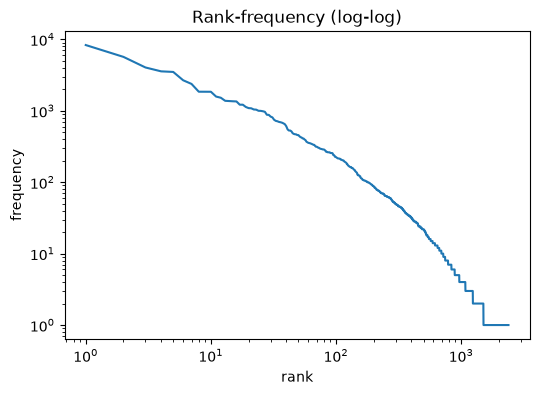

In [41]:
import matplotlib.pyplot as plt

counts_sorted = sorted(freq.values(), reverse=True)
plt.figure(figsize=(6, 4))
plt.loglog(range(1, len(counts_sorted) + 1), counts_sorted)
plt.xlabel("rank")
plt.ylabel("frequency")
plt.title("Rank-frequency (log-log)")
plt.show()

In [42]:
def normalize(s):
    # normalisation = lowercase + remove punctuation + single spaces
    return " ".join(re.findall(r"[a-z0-9]+", s.lower()))

train["norm"] = train["text"].apply(normalize)
test["norm"] = test["text"].apply(normalize)

exact = set(train["text"]) & set(test["text"])
near = set(train["norm"]) & set(test["norm"])
print("exact duplicates train/test:", len(exact))
print("near duplicates after normalisation:", len(near))
print("exact duplicates inside train:", train["text"].duplicated().sum())
print(list(near)[:5])

exact duplicates train/test: 0
near duplicates after normalisation: 25
exact duplicates inside train: 0
['what businesses accept this card', 'how do i unblock my pin', 'can i use apple pay to top up', 'can i top up by cheque', 'my top up didn t work']


In [43]:
from sklearn.feature_extraction.text import TfidfVectorizer

# v1: your rule-based tokenizer (words, contractions like don't, numbers)
V1 = re.compile(r"[a-z]+(?:'[a-z]+)?|\d+(?:[.,]\d+)?")
def tok_v1(s):
    return V1.findall(s.lower())

# v2: the fix (keeps currency symbols with amounts, and hyphenated words like top-up)
V2 = re.compile(r"[£$€]?\d+(?:[.,]\d+)*[£$€%]?|[a-z]+(?:['\-][a-z]+)*")
def tok_v2(s):
    return V2.findall(s.lower())

# scikit-learn default (pattern is r"(?u)\b\w\w+\b": words of 2+ letters only)
default_tok = TfidfVectorizer().build_analyzer()
def tok_default(s):
    return default_tok(s)

print(tok_v1("I don't know why my top-up of £20.50 failed"))
print(tok_v2("I don't know why my top-up of £20.50 failed"))
print(tok_default("I don't know why my top-up of £20.50 failed"))

['i', "don't", 'know', 'why', 'my', 'top', 'up', 'of', '20.50', 'failed']
['i', "don't", 'know', 'why', 'my', 'top-up', 'of', '£20.50', 'failed']
['don', 'know', 'why', 'my', 'top', 'up', 'of', '20', '50', 'failed']


In [44]:
# automatically pick 2 messages from each "difficult" category (seed 42)
masks = {
    "currency":    train["text"].str.contains(r"[£$€]"),
    "digits":      train["text"].str.contains(r"\d") & ~train["text"].str.contains(r"[£$€]"),
    "contraction": train["text"].str.contains(r"[a-z]'[a-z]", case=False),
    "hyphen":      train["text"].str.contains(r"[a-z]-[a-z]", case=False),
    "typo?":       train["tokens"].apply(lambda toks: any(freq[t] == 1 for t in toks)),
}

hard = []
for name, m in masks.items():
    for text in train[m].sample(2, random_state=SEED)["text"]:
        hard.append((name, text))

for name, text in hard:
    print(f"[{name}] {text}")
    print("  v1     :", tok_v1(text))
    print("  v2     :", tok_v2(text))
    print("  default:", tok_default(text))
    print()

[currency] I tried to withdraw $100 but only got $20. What happened?
  v1     : ['i', 'tried', 'to', 'withdraw', '100', 'but', 'only', 'got', '20', 'what', 'happened']
  v2     : ['i', 'tried', 'to', 'withdraw', '$100', 'but', 'only', 'got', '$20', 'what', 'happened']
  default: ['tried', 'to', 'withdraw', '100', 'but', 'only', 'got', '20', 'what', 'happened']

[currency] I was charged $1 in a transaction.
  v1     : ['i', 'was', 'charged', '1', 'in', 'a', 'transaction']
  v2     : ['i', 'was', 'charged', '$1', 'in', 'a', 'transaction']
  default: ['was', 'charged', 'in', 'transaction']

[digits] Hello-Can you please help me get a refund from this merchant?  I ordered a product and would like to return it. I have been unsuccessful in getting the merchant to return my request for the past several days.  I understand it can take up to 45 days to process the dispute and issue a refund, however, if this can be expedited faster it would be very helpful to me.
  v1     : ['hello', 'can', 'yo

In [45]:
a = "why was my top-up declined"
b = "why was my top up declined"
print("v2 on a:", tok_v2(a))
print("v2 on b:", tok_v2(b))
print("same tokens?", tok_v2(a) == tok_v2(b))
print("default on a:", tok_default(a))
print("default on b:", tok_default(b))
print("same tokens?", tok_default(a) == tok_default(b))

v2 on a: ['why', 'was', 'my', 'top-up', 'declined']
v2 on b: ['why', 'was', 'my', 'top', 'up', 'declined']
same tokens? False
default on a: ['why', 'was', 'my', 'top', 'up', 'declined']
default on b: ['why', 'was', 'my', 'top', 'up', 'declined']
same tokens? True


In [46]:
from sklearn.model_selection import train_test_split

tr, val = train_test_split(train, test_size=0.15, stratify=train["team"], random_state=SEED)

X_tr, y_tr = tr["text"], tr["team"]
X_val, y_val = val["text"], val["team"]
X_test, y_test = test["text"], test["team"]

print(len(tr), len(val), len(test))
print((tr["team"].value_counts(normalize=True) * 100).round(1))
print((val["team"].value_counts(normalize=True) * 100).round(1))

8502 1501 3080
team
Paiements    56.8
Cartes       22.5
Compte       12.7
Securite      8.0
Name: proportion, dtype: float64
team
Paiements    56.8
Cartes       22.6
Compte       12.7
Securite      8.0
Name: proportion, dtype: float64


In [47]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score

pipe = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("clf", LogisticRegression(max_iter=1000, random_state=SEED)),
])
pipe.fit(X_tr, y_tr)               # vocabulary + IDF + weights: learned on train ONLY
pred = pipe.predict(X_val)

vocab_train = len(pipe.named_steps["tfidf"].vocabulary_)
f1_correct = f1_score(y_val, pred, average="macro")
print("vocab (train only):", vocab_train)
print("accuracy:", round(accuracy_score(y_val, pred), 4))
print("macro-F1:", round(f1_correct, 4))

vocab (train only): 2184
accuracy: 0.9467
macro-F1: 0.9208


In [48]:
# LEAKY: the vectorizer sees train + validation + test texts when learning vocabulary and IDF
leaky_vec = TfidfVectorizer().fit(pd.concat([X_tr, X_val, X_test]))
clf_leaky = LogisticRegression(max_iter=1000, random_state=SEED)
clf_leaky.fit(leaky_vec.transform(X_tr), y_tr)
pred_leaky = clf_leaky.predict(leaky_vec.transform(X_val))

vocab_all = len(leaky_vec.vocabulary_)
f1_leaky = f1_score(y_val, pred_leaky, average="macro")
print("vocab (train+val+test):", vocab_all)
print("macro-F1 correct:", round(f1_correct, 4))
print("macro-F1 leaky  :", round(f1_leaky, 4))

# saved for results.json later
leakage = {"vocab_train": vocab_train, "vocab_all": vocab_all,
           "macro_f1_correct": float(f1_correct), "macro_f1_leaky": float(f1_leaky)}

vocab (train+val+test): 2532
macro-F1 correct: 0.9208
macro-F1 leaky  : 0.9224


## Part D: interpretation

**Is a random split acceptable?** Mostly yes: BANKING77 messages are independent short messages, with no user id or timestamp, so there is nothing to group by. Limit: near-duplicates/paraphrases can land in both train and validation and make the score look better than it is.

**Leakage experiment.** The leaky vocabulary is larger and the macro-F1 changes only slightly. A small gap does NOT prove the leak is harmless: the protocol is still invalid because the model gets information from data it should not know (test vocabulary and IDF statistics), and in production the future messages do not exist at training time. TF-IDF leakage is mild because no labels are used, but the same mistake with label-dependent steps (feature selection, target encoding) can inflate scores a lot. The rule is: every learned step goes inside the Pipeline and is fitted on train only.

In [49]:
import warnings
warnings.filterwarnings("ignore")   # hides harmless sklearn warnings

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.dummy import DummyClassifier

base = DummyClassifier(strategy="most_frequent").fit(np.zeros((len(X_tr), 1)), y_tr)
pb = base.predict(np.zeros((len(X_val), 1)))

baseline_val = {"accuracy": float(accuracy_score(y_val, pb)),
                "macro_f1": float(f1_score(y_val, pb, average="macro"))}
print("most frequent class:", y_tr.value_counts().idxmax())
print(baseline_val)

most frequent class: Paiements
{'accuracy': 0.5676215856095936, 'macro_f1': 0.18104547386315342}


In [50]:
val_grid = []
for model_name, Vec in [("bow", CountVectorizer), ("tfidf", TfidfVectorizer)]:
    for sw in [False, True]:
        for ng in [(1, 1), (1, 2)]:
            for C in [0.1, 1, 10]:
                p = Pipeline([
                    ("vec", Vec(stop_words="english" if sw else None, ngram_range=ng)),
                    ("clf", LogisticRegression(C=C, max_iter=1000, random_state=SEED)),
                ])
                p.fit(X_tr, y_tr)
                f1 = f1_score(y_val, p.predict(X_val), average="macro")
                val_grid.append({"model": model_name, "stop_words": sw,
                                 "ngram": list(ng), "C": C, "macro_f1": float(f1)})

grid_df = pd.DataFrame(val_grid).sort_values("macro_f1", ascending=False)
print(grid_df.round(4).to_string(index=False))

chosen = grid_df.iloc[0].to_dict()
chosen = {"model": chosen["model"], "stop_words": bool(chosen["stop_words"]),
          "ngram": list(chosen["ngram"]), "C": float(chosen["C"]),
          "macro_f1": float(chosen["macro_f1"])}
print("\nCHOSEN:", chosen)

model  stop_words  ngram    C  macro_f1
  bow       False [1, 2] 10.0    0.9585
  bow       False [1, 2]  1.0    0.9564
tfidf       False [1, 2] 10.0    0.9552
tfidf       False [1, 1] 10.0    0.9528
  bow       False [1, 1] 10.0    0.9458
  bow       False [1, 1]  1.0    0.9411
tfidf        True [1, 2] 10.0    0.9386
  bow        True [1, 2]  1.0    0.9350
tfidf        True [1, 1] 10.0    0.9346
  bow        True [1, 2] 10.0    0.9344
  bow       False [1, 2]  0.1    0.9303
  bow        True [1, 1] 10.0    0.9291
tfidf       False [1, 1]  1.0    0.9208
  bow        True [1, 1]  1.0    0.9199
tfidf       False [1, 2]  1.0    0.9142
tfidf        True [1, 1]  1.0    0.9142
  bow       False [1, 1]  0.1    0.9097
tfidf        True [1, 2]  1.0    0.9071
  bow        True [1, 2]  0.1    0.8767
  bow        True [1, 1]  0.1    0.8702
tfidf       False [1, 1]  0.1    0.7895
tfidf        True [1, 1]  0.1    0.7652
tfidf        True [1, 2]  0.1    0.6640
tfidf       False [1, 2]  0.1    0.6602


In [51]:
an_sw = TfidfVectorizer(stop_words="english").build_analyzer()   # removes stop words
an_no = TfidfVectorizer().build_analyzer()                        # keeps them

sw = set(TfidfVectorizer(stop_words="english").get_stop_words())
for w in ["not", "no", "yet", "still", "my", "how", "why"]:
    print(w, "is a stop word:", w in sw)

ex = train[train["text"].str.contains(r"\b(?:not|no|yet|still)\b", case=False)].sample(6, random_state=SEED)
print()
for _, r in ex.iterrows():
    print(r["team"], "|", r["text"])
    print("   kept   :", an_no(r["text"]))
    print("   removed:", an_sw(r["text"]))

not is a stop word: True
no is a stop word: True
yet is a stop word: True
still is a stop word: True
my is a stop word: True
how is a stop word: True
why is a stop word: True

Paiements | I did not receive the correct amount for the exchange rate.
   kept   : ['did', 'not', 'receive', 'the', 'correct', 'amount', 'for', 'the', 'exchange', 'rate']
   removed: ['did', 'receive', 'correct', 'exchange', 'rate']
Paiements | I could not get the cash I wanted
   kept   : ['could', 'not', 'get', 'the', 'cash', 'wanted']
   removed: ['cash', 'wanted']
Securite | I have a direct debit that I did not set up
   kept   : ['have', 'direct', 'debit', 'that', 'did', 'not', 'set', 'up']
   removed: ['direct', 'debit', 'did', 'set']
Paiements | How long do EU transfers take? I bought something online a couple days ago , sent the money immediately online but the seller says it is still not there yet
   kept   : ['how', 'long', 'do', 'eu', 'transfers', 'take', 'bought', 'something', 'online', 'couple', 'da

In [52]:
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support

LABELS = ["Cartes", "Compte", "Paiements", "Securite"]

# rebuild the chosen config from Cell 19 and fit on train only
Vec = CountVectorizer if chosen["model"] == "bow" else TfidfVectorizer
final = Pipeline([
    ("vec", Vec(stop_words="english" if chosen["stop_words"] else None,
                ngram_range=tuple(chosen["ngram"]))),
    ("clf", LogisticRegression(C=chosen["C"], max_iter=1000, random_state=SEED)),
])
final.fit(X_tr, y_tr)
pred_test = final.predict(X_test)

acc = accuracy_score(y_test, pred_test)
macro = f1_score(y_test, pred_test, average="macro")
micro = f1_score(y_test, pred_test, average="micro")
print("accuracy:", round(acc, 4), "| macro-F1:", round(macro, 4), "| micro-F1:", round(micro, 4))
print()
print(classification_report(y_test, pred_test, labels=LABELS, digits=4))

cm = confusion_matrix(y_test, pred_test, labels=LABELS)
print(pd.DataFrame(cm, index=["true_" + l for l in LABELS], columns=["pred_" + l for l in LABELS]))

# saved for results.json
p, r, f, s = precision_recall_fscore_support(y_test, pred_test, labels=LABELS, zero_division=0)
per_class = {l: {"precision": float(p[i]), "recall": float(r[i]), "f1": float(f[i]), "support": int(s[i])}
             for i, l in enumerate(LABELS)}
test_results = {"accuracy": float(acc), "macro_f1": float(macro), "micro_f1": float(micro),
                "per_class": per_class, "confusion_matrix": cm.tolist()}

accuracy: 0.9692 | macro-F1: 0.9573 | micro-F1: 0.9692

              precision    recall  f1-score   support

      Cartes     0.9771    0.9655    0.9713       840
      Compte     0.9576    0.9750    0.9662       440
   Paiements     0.9697    0.9840    0.9768      1560
    Securite     0.9589    0.8750    0.9150       240

    accuracy                         0.9692      3080
   macro avg     0.9658    0.9499    0.9573      3080
weighted avg     0.9691    0.9692    0.9690      3080

                pred_Cartes  pred_Compte  pred_Paiements  pred_Securite
true_Cartes             811            7              20              2
true_Compte               3          429               7              1
true_Paiements           10            9            1535              6
true_Securite             6            3              21            210


In [53]:
k = LABELS.index("Securite")
TP = int(cm[k, k])
FP = int(cm[:, k].sum() - TP)
FN = int(cm[k, :].sum() - TP)

P = TP / (TP + FP)
R = TP / (TP + FN)
F1 = 2 * P * R / (P + R)

print(f"TP={TP}  FP={FP}  FN={FN}")
print(f"Precision = TP/(TP+FP) = {TP}/{TP+FP} = {P:.4f}")
print(f"Recall    = TP/(TP+FN) = {TP}/{TP+FN} = {R:.4f}")
print(f"F1 = 2*P*R/(P+R) = {F1:.4f}")
print("sklearn says:", {k_: round(v, 4) for k_, v in per_class["Securite"].items()})

TP=210  FP=9  FN=30
Precision = TP/(TP+FP) = 210/219 = 0.9589
Recall    = TP/(TP+FN) = 210/240 = 0.8750
F1 = 2*P*R/(P+R) = 0.9150
sklearn says: {'precision': 0.9589, 'recall': 0.875, 'f1': 0.915, 'support': 240}


  t  precision  recall
0.1      0.831   0.942
0.2      0.917   0.925
0.3      0.957   0.917
0.4      0.982   0.900
0.5      0.991   0.900
0.6      0.991   0.883
0.7      1.000   0.850
0.8      1.000   0.817


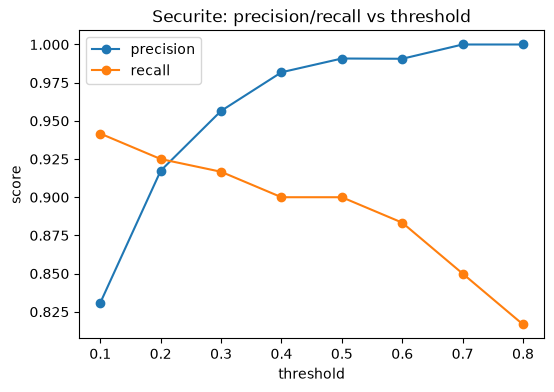

In [54]:
from sklearn.metrics import precision_score, recall_score

sec_idx = list(final.classes_).index("Securite")
proba_val = final.predict_proba(X_val)[:, sec_idx]       # predicted probability of Securite
y_val_sec = (y_val == "Securite").values                  # one-vs-rest: Securite or not

threshold_securite_val = []
for t in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    flagged = proba_val >= t
    threshold_securite_val.append({
        "t": t,
        "precision": float(precision_score(y_val_sec, flagged, zero_division=0)),
        "recall": float(recall_score(y_val_sec, flagged)),
    })

thr = pd.DataFrame(threshold_securite_val)
print(thr.round(3).to_string(index=False))

plt.figure(figsize=(6, 4))
plt.plot(thr["t"], thr["precision"], marker="o", label="precision")
plt.plot(thr["t"], thr["recall"], marker="o", label="recall")
plt.xlabel("threshold"); plt.ylabel("score"); plt.title("Securite: precision/recall vs threshold")
plt.legend(); plt.show()

In [55]:
# find two short messages from the corpus that share at least 2 words
short = tr[tr["tokens"].apply(len) <= 6]["tokens"].tolist()[:300]
pair = None
for i in range(len(short)):
    for j in range(i + 1, len(short)):
        if len(set(short[i]) & set(short[j])) >= 2 and short[i] != short[j]:
            pair = (short[i], short[j])
            break
    if pair:
        break

a, b = pair
print("message A:", a)
print("message B:", b)

# explicit shared vocabulary + count vectors
vocab = sorted(set(a) | set(b))
va = [a.count(w) for w in vocab]
vb = [b.count(w) for w in vocab]
print(pd.DataFrame({"word": vocab, "A": va, "B": vb}).to_string(index=False))

# by hand: cos = (A . B) / (|A| * |B|)
dot = sum(x * y for x, y in zip(va, vb))
norm_a = sum(x * x for x in va) ** 0.5
norm_b = sum(y * y for y in vb) ** 0.5
cos_manual = dot / (norm_a * norm_b)
print(f"\ndot = {dot} | |A| = {norm_a:.4f} | |B| = {norm_b:.4f}")
print(f"cosine (manual) = {dot} / ({norm_a:.4f} x {norm_b:.4f}) = {cos_manual:.4f}")

# check with NumPy
cos_np = np.dot(va, vb) / (np.linalg.norm(va) * np.linalg.norm(vb))
print(f"cosine (numpy)  = {cos_np:.4f}")

message A: ['when', 'can', 'i', 'expect', 'my', 'refund']
message B: ['i', 'need', 'to', 'change', 'my', 'data']
  word  A  B
   can  1  0
change  0  1
  data  0  1
expect  1  0
     i  1  1
    my  1  1
  need  0  1
refund  1  0
    to  0  1
  when  1  0

dot = 2 | |A| = 2.4495 | |B| = 2.4495
cosine (manual) = 2 / (2.4495 x 2.4495) = 0.3333
cosine (numpy)  = 0.3333


In [56]:
from sklearn.metrics.pairwise import cosine_similarity

vec_ret = TfidfVectorizer().fit(X_tr)          # fitted on train only (no leakage)
M_tr = vec_ret.transform(X_tr)

queries = val.sample(5, random_state=SEED)
hits = 0
for _, row in queries.iterrows():
    q = vec_ret.transform([row["text"]])
    sims = cosine_similarity(q, M_tr)[0]
    top3 = np.argsort(-sims)[:3]
    teams = y_tr.iloc[top3].tolist()
    hit = row["team"] in teams
    hits += int(hit)
    print(f"QUERY [{row['team']}]: {row['text']}")
    for rank, idx in enumerate(top3):
        print(f"   {rank+1}. cos={sims[idx]:.3f} [{y_tr.iloc[idx]}] {X_tr.iloc[idx]}")
    print("   -> same team in top 3:", hit, "\n")

retrieval_recall_at_3 = hits / 5
print("Recall@3 =", retrieval_recall_at_3)

QUERY [Cartes]: Please tell me about disposable cards.
   1. cos=0.708 [Cartes] Please tell me how disposable virtual cards work?
   2. cos=0.696 [Cartes] Can you tell me about these disposable virtual cards?
   3. cos=0.636 [Cartes] Can you tell me more info about virtual disposable cards?
   -> same team in top 3: True 

QUERY [Securite]: I left my phone somewhere and can't use the app.
   1. cos=0.548 [Securite] My phone was left at a hotel and I can't access the app.
   2. cos=0.523 [Securite] left my phone at hotel, cant use app
   3. cos=0.520 [Securite] My phone was left behind.  Can I still use my card?
   -> same team in top 3: True 

QUERY [Cartes]: Was there a number to track that I could get?
   1. cos=0.464 [Cartes] Is there a way to track my card?
   2. cos=0.461 [Cartes] Can I track the card that was just sent to me?
   3. cos=0.428 [Cartes] Will I be able to track the card that was sent to me?
   -> same team in top 3: True 

QUERY [Cartes]: Do I get Visa or Mastercard?

In [57]:

own = [
    # ==========================
    # FRENCH (10 MESSAGES)
    # ==========================
    ("fr", "Ma carte n'est toujours pas arrivée après deux semaines.", "Cartes"),
    ("fr", "Je n'arrive plus à me connecter à mon compte bancaire.", "Compte"),
    ("fr", "Mon virement est toujours en attente depuis hier.", "Paiements"),
    ("fr", "Je vois un paiement de 150 euros que je n'ai jamais effectué.", "Securite"),
    ("fr", "Ma carte bancaire est bloquée et je ne peux plus payer.", "Cartes"),
    ("fr", "J'ai oublié mon mot de passe et je ne peux pas le récupérer.", "Compte"),
    ("fr", "L'argent a été débité mais le bénéficiaire n'a rien reçu.", "Paiements"),
    ("fr", "J'ai perdu ma carte bancaire, quelqu'un pourrait l'utiliser.", "Securite"),
    ("fr", "Je voudrais changer le numéro de téléphone associé à mon compte.", "Compte"),
    ("fr", "Il y a un retrait de 200 euros que je ne reconnais pas.", "Securite"),

    # ==========================
    # DARIJA / TUNISIAN ARABIZI (10)
    # ==========================
    ("darija", "Carte mte3i mazelt ma wosletnich men jem3tin.", "Cartes"),
    ("darija", "Ma najamch nodkhol lel compte mte3i, password ma ya9belch.", "Compte"),
    ("darija", "Ba3atht flous par virement ama mazelt ma woslouch.", "Paiements"),
    ("darija", "Fama paiement fel carte mte3i ena ma 3maltouch.", "Securite"),
    ("darija", "Carte bancaire mte3i bloquée, chnowa na3mel?", "Cartes"),
    ("darija", "Nsit password w ma najamch n3awed n7ell compte mte3i.", "Compte"),
    ("darija", "El flous tna7aw mel compte ama el virement mazal pending.", "Paiements"),
    ("darija", "Dha3etli carte w khayef chkoun yesta3melha, bloquiwhali.", "Securite"),
    ("darija", "Nheb nbadel numero telephone mte3 compte bancaire.", "Compte"),
    ("darija", "Fama retrait 100dt mel compte mte3i w ena ma 5dhit chay.", "Securite"),

    # ==========================
    # ENGLISH WITH TYPOS (10)
    # ==========================
    ("en_typo", "my card still hasnt arived after 2 weeks", "Cartes"),
    ("en_typo", "i cant acces my bank accout anymore", "Compte"),
    ("en_typo", "my transfre has not arived yet", "Paiements"),
    ("en_typo", "theres a payment i didnt made on my statment", "Securite"),
    ("en_typo", "my card keep geting declined for no reason", "Cartes"),
    ("en_typo", "i forgot my passwrod and cant login", "Compte"),
    ("en_typo", "money was dedcuted but the transfer is not compleated", "Paiements"),
    ("en_typo", "somebody stole my bank card pls block it now", "Securite"),
    ("en_typo", "i need to change my phone numer linked to my accout", "Compte"),
    ("en_typo", "i see a withdrawl i never made on my bank statment", "Securite"),
]

own_df = pd.DataFrame(own, columns=["lang", "text", "team"])

print(len(own_df), "messages")
print(own_df.groupby(["lang", "team"]).size())

assert len(own_df) == 30, "You need exactly 30 messages"


30 messages
lang     team     
darija   Cartes       2
         Compte       3
         Paiements    2
         Securite     3
en_typo  Cartes       2
         Compte       3
         Paiements    2
         Securite     3
fr       Cartes       2
         Compte       3
         Paiements    2
         Securite     3
dtype: int64


In [58]:
own_pred = final.predict(own_df["text"])
own_df["pred"] = own_pred
own_df["ok"] = own_df["team"] == own_df["pred"]

own_acc = accuracy_score(own_df["team"], own_pred)
own_macro = f1_score(own_df["team"], own_pred, average="macro")
print("own set accuracy:", round(own_acc, 4), "| macro-F1:", round(own_macro, 4))
print()
print(own_df.groupby("lang")["ok"].mean().round(2))   # accuracy per language

own_set = {"n": 30, "accuracy": float(own_acc), "macro_f1": float(own_macro)}

own set accuracy: 0.4667 | macro-F1: 0.4374

lang
darija     0.4
en_typo    0.7
fr         0.3
Name: ok, dtype: float64


In [59]:
# errors on the official test set
mask = pred_test != y_test.values
test_err = test[mask].copy()
test_err["pred"] = pred_test[mask]
print("number of test errors:", len(test_err))
print("TEST ERRORS (sample of 12):")
print(test_err.sample(12, random_state=SEED)[["text", "team", "pred"]].to_string(index=False))

# errors on your own set
print("\nOWN SET ERRORS:")
print(own_df[~own_df["ok"]][["lang", "text", "team", "pred"]].to_string(index=False))

number of test errors: 95
TEST ERRORS (sample of 12):
                                                                                                                 text      team      pred
                                                             I was taking out funds and was unable to regain my card.    Cartes Paiements
                                                                                               Why did I get blocked?    Cartes Paiements
                            What would the approximate delivery date be if I transferred something urgently to China? Paiements    Cartes
My card is being declined for a purchase. I bought items before and the card worked. Do you know what the problem is? Paiements    Cartes
                                 I'm starting to think my card is lost because it still hasn't arrived, can you help?    Cartes  Securite
                                                                The NFC payment wouldn't work on the bus today. Help? 

## Part H: error analysis

| # | Message | True | Predicted | Probable cause | Level |
|---|---------|------|-----------|----------------|-------|
| 1 | ...     | ...  | ...       | ...            | ...   |

In [60]:
def team_counts(df):
    return {l: int((df["team"] == l).sum()) for l in LABELS}

results = {
    "seed": SEED,
    "labels": LABELS,
    "counts": {"train": team_counts(tr), "val": team_counts(val), "test": team_counts(test)},
    "baseline_val": baseline_val,
    "val_grid": val_grid,
    "chosen": chosen,
    "test": test_results,
    "leakage": leakage,
    "threshold_securite_val": threshold_securite_val,
    "retrieval_recall_at_3": float(retrieval_recall_at_3),
    "own_set": own_set,
}

with open("results.json", "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2, ensure_ascii=False)

# quick check: all required keys are present
required = ["seed", "labels", "counts", "baseline_val", "val_grid", "chosen", "test",
            "leakage", "threshold_securite_val", "retrieval_recall_at_3", "own_set"]
print("missing keys:", [k for k in required if k not in results])
print("results.json written,", len(val_grid), "grid rows")

missing keys: []
results.json written, 24 grid rows


In [61]:
M_val = vec_ret.transform(X_val)
top3_all = []
for start in range(0, M_val.shape[0], 500):
    S = cosine_similarity(M_val[start:start+500], M_tr)
    top3_all.append(np.argsort(-S, axis=1)[:, :3])
top3_all = np.vstack(top3_all)

y_tr_arr = y_tr.values
hit_all = np.array([yv in y_tr_arr[t] for yv, t in zip(y_val.values, top3_all)])
recall3_full = hit_all.mean()
print("Recall@3 on full validation:", round(recall3_full, 4))
print("failures:", int((~hit_all).sum()), "of", len(hit_all))

for i in np.where(~hit_all)[0][:4]:
    print("\nQUERY [%s]: %s" % (y_val.iloc[i], X_val.iloc[i]))
    for j in top3_all[i]:
        print("    [%s] %s" % (y_tr.iloc[j], X_tr.iloc[j]))

Recall@3 on full validation: 0.9813
failures: 28 of 1501

QUERY [Compte]: I can't access my account.
    [Paiements] Why can't my beneficiary access my account?
    [Paiements] Who can have access to top up my account?
    [Paiements] Why can't my beneficiary get access?

QUERY [Cartes]: Is the card welcomed by everybody?
    [Paiements] How do I to up by card?
    [Paiements] what is the fee for topping up by card?
    [Paiements] Is it possible to top up by card?

QUERY [Paiements]: What kind of fees will I pay when I transfer?
    [Cartes] What kind of businesses will take my card?
    [Cartes] If I get another card, what kind of fees am I looking at?
    [Compte] What kind of money can I hold?

QUERY [Securite]: Why is there some cash that I did not deposit in my account?
    [Paiements] Why did the cash deposit not show up in my account?
    [Paiements] Why did my cash deposit not show up?
    [Paiements] I made a cash deposit to my account but it is not there


In [62]:
rows = []
for t in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    flagged = proba_val >= t
    tp = int((flagged & y_val_sec).sum())
    fp = int((flagged & ~y_val_sec).sum())
    fn = int((~flagged & y_val_sec).sum())
    p, r = tp / (tp + fp), tp / (tp + fn)
    rows.append({"t": t, "TP": tp, "FP": fp, "FN": fn,
                 "F1": round(2*p*r/(p+r), 3), "F2": round(5*p*r/(4*p+r), 3)})
print(pd.DataFrame(rows).to_string(index=False))

  t  TP  FP  FN    F1    F2
0.1 113  23   7 0.883 0.917
0.2 111  10   9 0.921 0.923
0.3 110   5  10 0.936 0.924
0.4 108   2  12 0.939 0.915
0.5 108   1  12 0.943 0.917
0.6 106   1  14 0.934 0.903
0.7 102   0  18 0.919 0.876
0.8  98   0  22 0.899 0.848


In [63]:
vocab = final.named_steps["vec"].vocabulary_
for w in ["nfc", "stole", "stolen", "withdrawl", "withdrawal", "statment", "statement", "delivery", "hacked"]:
    print(f"{w:12s} in model vocabulary: {w in vocab}")

uni = CountVectorizer().build_analyzer()
def oov_rate(text):
    toks = uni(text)
    return sum(t not in vocab for t in toks) / max(len(toks), 1)
own_df["oov"] = own_df["text"].apply(oov_rate)
print("\nshare of out-of-vocabulary tokens:")
print(own_df.groupby("lang")["oov"].mean().round(2))
print("\npredictions on own set:")
print(own_df["pred"].value_counts())
print(classification_report(own_df["team"], own_pred, labels=LABELS, zero_division=0))

nfc          in model vocabulary: False
stole        in model vocabulary: True
stolen       in model vocabulary: True
withdrawl    in model vocabulary: True
withdrawal   in model vocabulary: True
statment     in model vocabulary: False
statement    in model vocabulary: True
delivery     in model vocabulary: True
hacked       in model vocabulary: True

share of out-of-vocabulary tokens:
lang
darija     0.97
en_typo    0.19
fr         0.91
Name: oov, dtype: float64

predictions on own set:
pred
Paiements    19
Compte        7
Cartes        3
Securite      1
Name: count, dtype: int64
              precision    recall  f1-score   support

      Cartes       0.67      0.33      0.44         6
      Compte       0.71      0.56      0.62         9
   Paiements       0.32      1.00      0.48         6
    Securite       1.00      0.11      0.20         9

    accuracy                           0.47        30
   macro avg       0.67      0.50      0.44        30
weighted avg       0.71      0.4